<div style="text-align: center; width: 100%;">
<h1 style="font-weight: 900; margin-bottom: 20px; text-align: center;"><b>FDR4VGT-CLOUD quick start</b></h1>
<img src="https://huggingface.co/front/assets/huggingface_logo-noborder.svg" alt="Hugging Face logo" style="width: 120px;">
</div>

This notebook loads the published cloud-detection model from Hugging Face and runs inference on the sample image.

## 1. Install dependencies

In [1]:
import sys
!{sys.executable} -m pip install mlstac==0.4.9 rasterio "torch>=2.7.0" "segmentation-models-pytorch>=0.5.0" matplotlib


## 2. Load the model

In [2]:
import mlstac

loader = mlstac.load(
    "https://huggingface.co/isp-uv-es/FDR4VGT-CLOUD/resolve/main/single/multisensor_single_1dpwdeeplabv3.json"
)
downloaded = loader.download(output_dir="fdr4vgt_model")
model = downloaded.compiled_model(device="cpu")
print("Model loaded. Ensemble:", downloaded.is_ensemble)

Model loaded. Ensemble: False


## 3. Download the sample image

In [3]:
from huggingface_hub import hf_hub_download

sample_path = hf_hub_download(
    repo_id="isp-uv-es/FDR4VGT-CLOUD",
    filename="ensemble/rgb.tif",
)
print("Sample image:", sample_path)

Sample image: /data/users/julio/.cache/huggingface/hub/models--isp-uv-es--FDR4VGT-CLOUD/snapshots/0205c4c99bde8477230d52ff7a54498aa8c5609f/ensemble/rgb.tif


## 4. Read a 512x512 crop and run inference

In [4]:
import rasterio as rio
import torch

with rio.open(sample_path) as src:
    image = src.read(window=rio.windows.Window(0, 0, 512, 512))

image_t = torch.from_numpy(image).float().unsqueeze(0)

with torch.no_grad():
    prob = model(image_t)

print("Output shape:", prob.shape)
print("Probability range:", prob.min().item(), prob.max().item())

Output shape: torch.Size([1, 1, 512, 512])
Probability range: 3.838151574342419e-09 0.9999939203262329


## 5. Plot the RGB composite and the cloud probability

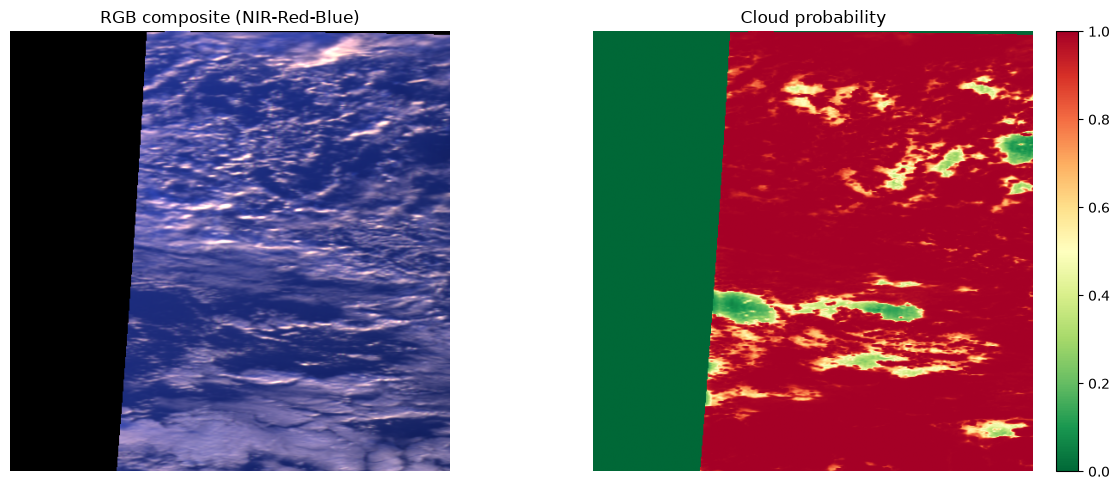

In [5]:
import matplotlib.pyplot as plt
import numpy as np

rgb = np.stack([image[2], image[1], image[0]], axis=-1)
rgb = np.clip(rgb, 0, 1)
prob_np = prob.squeeze().numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(rgb)
axes[0].set_title("RGB composite (NIR-Red-Blue)")
axes[0].axis("off")

im = axes[1].imshow(prob_np, cmap="RdYlGn_r", vmin=0, vmax=1)
axes[1].set_title("Cloud probability")
axes[1].axis("off")
fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
fig.tight_layout()
plt.show()

## Next steps

- Try the full `predict_large` helper in `src/fdr4vgt_cloud/inference.py` for tiled inference on large rasters.
- Read `docs/model.md` for architecture details and `docs/dataset.md` for the data schema.